# PA3 Task 1 — LLM fine-tuning: full FT, L2-SP, LoRA (r=4, r=16), OPLoRA

Qwen3-0.6B fine-tuned on 40k MetaMathQA examples (1 epoch, 1250 updates of 32), evaluated zero-shot with
lm-eval on GSM8K-CoT (target task) and HellaSwag / BoolQ / ARC-Easy (forgetting probes).

**Where it ran.** All training and evaluation ran on Kaggle (free tier, 2× T4), two jobs in parallel per session
(one per GPU) using the code below:

| Kaggle job | GPU 0 | GPU 1 |
|---|---|---|
| `pa3-task1-lora` | train lora4 → evals (BoolQ OOM'd, redone in part2) | train lora16 → evals (same) |
| `pa3-task1-part2` (resumes from job 1's output) | train + eval oplora | remaining lora4/lora16 evals, baseline evals |
| `pa3-task1-full` | train full → eval full_mid (step 625), full | train + eval l2sp |

Free Colab was tried first for full/l2sp but reclaimed the VM mid-run twice, so everything was moved to Kaggle.
The cells further down print the real logs from those jobs and compute every table/plot from the saved result files
in `results/`.

**Changes vs. the original notebook code (needed for a 15 GB T4 / Kaggle's 20 GB output limit, no effect on the method):**
1. `train.py`: the SFT loss computes `lm_head` + cross-entropy only on response positions, in 512-row chunks that are
   recomputed in backward (`chunked_ce`). Same loss/gradients — update 1 reproduces the original code exactly
   (`sft=1.0285, gn=33.29`) — but no (B, L, 151936) fp16 + fp32 logit copies, which OOM'd full FT.
2. `eval.py`: log-likelihood tasks use batch size 8 (BoolQ OOM'd at 32); batch size does not change loglik scores.
   GSM8K generation keeps batch 32.
3. `train.py --light_milestones` (used for full / l2sp only): quarter-epoch checkpoints are stored as fp16 weights
   instead of weights + optimizer state (7.2 GB each), and the rolling `ckpt_latest.pt` is deleted after the run
   finishes. The step-625 export for `full_mid` is taken from the live fp32 weights, so its displacement is exact.

In [1]:
import os
os.makedirs("pa3", exist_ok=True)

In [2]:
%%writefile pa3/common.py
"""Shared constants and helpers for Task 1 (resumable fine-tuning pipeline)."""
import json
import os
import re
import shutil

import torch

MODEL = "Qwen/Qwen3-0.6B"
SEED = 6304
N_TRAIN = 40_000
MAX_LEN = 2048
MICRO_BS = 2
ACCUM = 16
BATCH = MICRO_BS * ACCUM            # 32
TOTAL_UPDATES = N_TRAIN // BATCH    # 1250
WARMUP = 38
MILESTONES = [312, 625, 937, 1250]
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# method -> (peak lr, lambda, adapter rank, alpha, oplora)
METHODS = {
    "full":    dict(lr=2e-5, lam=0.0,  r=None, alpha=None, oplora=False),
    "l2sp":    dict(lr=2e-5, lam=1e-3, r=None, alpha=None, oplora=False),
    "lora4":   dict(lr=2e-4, lam=0.0,  r=4,    alpha=8,    oplora=False),
    "lora16":  dict(lr=2e-4, lam=0.0,  r=16,   alpha=32,   oplora=False),
    "oplora":  dict(lr=2e-4, lam=0.0,  r=16,   alpha=32,   oplora=True),
}
PROT_K = 128


def atomic_save(obj, path):
    """Write to a temp file then rename, so a disconnect mid-write never corrupts a checkpoint."""
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def atomic_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=str)
    os.replace(tmp, path)


def dir_size(path):
    if os.path.isfile(path):
        return os.path.getsize(path)
    return sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(path) for f in fs)


def norm_text(t):
    t = re.sub(r"[^\w\s]", " ", t.lower())
    return re.sub(r"\s+", " ", t).strip()


def build_dataset(tok, cache_path):
    """First 40k eligible MetaMathQA examples in source order (cached so every run/resume is identical)."""
    if os.path.exists(cache_path):
        return torch.load(cache_path)
    from datasets import load_dataset
    gsm_test = {norm_text(q) for q in load_dataset("openai/gsm8k", "main", split="test")["question"]}
    ds = load_dataset("meta-math/MetaMathQA", split="train")
    out, dropped = [], dict(empty=0, leak=0, long=0)
    for ex in ds:
        q, r = (ex["query"] or "").strip(), (ex["response"] or "").strip()
        if not q or not r:
            dropped["empty"] += 1
            continue
        if norm_text(q) in gsm_test or norm_text(ex.get("original_question") or "") in gsm_test:
            dropped["leak"] += 1
            continue
        prompt = tok.apply_chat_template([{"role": "user", "content": q}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
        p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
        r_ids = tok(r + "<|im_end|>", add_special_tokens=False)["input_ids"]
        if len(p_ids) + len(r_ids) > MAX_LEN:
            dropped["long"] += 1
            continue
        out.append((p_ids, r_ids))
        if len(out) == N_TRAIN:
            break
    data = dict(examples=out, dropped=dropped)
    print("dataset built:", len(out), "dropped:", dropped)
    atomic_save(data, cache_path)
    return data


def collate(examples, pad_id):
    L = max(len(p) + len(r) for p, r in examples)
    ids = torch.full((len(examples), L), pad_id, dtype=torch.long)
    labels = torch.full((len(examples), L), -100, dtype=torch.long)
    att = torch.zeros((len(examples), L), dtype=torch.long)
    for i, (p, r) in enumerate(examples):
        n = len(p) + len(r)
        ids[i, :n] = torch.tensor(p + r)
        labels[i, len(p):n] = torch.tensor(r)
        att[i, :n] = 1
    return ids, att, labels

Writing pa3/common.py


In [3]:
%%writefile pa3/train.py
"""Resumable SFT of Qwen3-0.6B on MetaMathQA: full, l2sp, lora4, lora16, oplora.

Re-running the same command after a disconnect continues from the newest checkpoint:
  * ckpt_latest.pt  - rolling checkpoint every --save_every updates (atomic write)
  * ckpt_step{312,625,937,1250}.pt - quarter-epoch recovery checkpoints
Each holds trainable weights, optimizer, scheduler, grad scaler, all RNG states and the
data position (the data order is fixed, so position == update index).
"""
import argparse
import json
import math
import os
import random
import shutil
import signal
import sys
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

import common as C

STOP = False


def _on_signal(*_):
    global STOP
    STOP = True
    print("signal received: will checkpoint after the current update and exit", flush=True)


# ----------------------------------------------------------------------------- adapters
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base, self.scale = base, alpha / r
        dev = base.weight.device
        self.A = nn.Parameter(torch.empty(r, base.in_features, device=dev, dtype=torch.float32))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=dev, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)
        self.Uk = self.Vk = None  # OPLoRA protected bases (fp32), set by attach_bases

    def effective(self):
        with torch.autocast("cuda", enabled=False):
            A, B = self.A, self.B
            if self.Uk is not None:
                B = B - self.Uk @ (self.Uk.T @ B)
                A = A - (A @ self.Vk) @ self.Vk.T
        return A, B

    def forward(self, x):
        A, B = self.effective()
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), A), B)


def add_adapters(model, r, alpha, dropout=0.05):
    mods = {}
    for name, mod in list(model.named_modules()):
        for cname, child in list(mod.named_children()):
            if cname in C.TARGETS and isinstance(child, nn.Linear):
                w = LoRALinear(child, r, alpha, dropout)
                setattr(mod, cname, w)
                mods[f"{name}.{cname}"] = w
    return mods


def attach_bases(mods, path, k):
    """Leading singular bases of W0, computed once in FP32 and cached on disk."""
    if os.path.exists(path):
        bases = torch.load(path, map_location="cpu")
        pre = bases.pop("_seconds")
    else:
        t0, bases = time.time(), {}
        for n, m in mods.items():
            U, S, Vh = torch.linalg.svd(m.base.weight.float(), full_matrices=False)
            bases[n] = (U[:, :k].contiguous().cpu(), Vh[:k].T.contiguous().cpu())
        pre = time.time() - t0
        C.atomic_save({**bases, "_seconds": pre}, path)
    for n, m in mods.items():
        m.Uk, m.Vk = (t.to(m.A.device) for t in bases[n])
    return pre, sum(u.numel() + v.numel() for u, v in bases.values()) * 4


# ----------------------------------------------------------------------------- helpers
def rng_state():
    return dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all())


def set_rng_state(s):
    random.setstate(s["py"]); np.random.set_state(s["np"])
    torch.set_rng_state(s["torch"]); torch.cuda.set_rng_state_all(s["cuda"])


def lr_lambda(step):
    if step < C.WARMUP:
        return (step + 1) / C.WARMUP
    p = (step - C.WARMUP) / max(1, C.TOTAL_UPDATES - C.WARMUP)
    return 0.5 * (1 + math.cos(math.pi * p))


def export_full(named_fp32, path, tok, p0=None):
    """Save an HF fp16 model dir from a {name: tensor} dict; returns displacement ||theta-theta0||_2."""
    from transformers import AutoConfig
    sd = {k: v.detach().half().cpu() for k, v in named_fp32.items()}
    cfg = AutoConfig.from_pretrained(C.MODEL)
    m = AutoModelForCausalLM.from_config(cfg, torch_dtype=torch.float16)
    m.load_state_dict({k: v for k, v in sd.items()}, strict=False)
    m.tie_weights()
    m.save_pretrained(path, safe_serialization=True)
    tok.save_pretrained(path)
    disp = None
    if p0 is not None:
        disp = math.sqrt(sum(((v.detach().float().cpu() - p0[k].float().cpu()) ** 2).sum().item()
                             for k, v in named_fp32.items()))
    return disp


def _ce_chunk(head, h, y):
    with torch.autocast("cuda", dtype=torch.float16):
        logits = head(h)
    return F.cross_entropy(logits.float(), y, reduction="sum")


def chunked_ce(head, h, y, rows=512):
    """Summed CE over response positions only, lm_head+CE recomputed per chunk in backward.
    Same math as full-vocab logits for every position, but never holds (B, L, V) fp16+fp32 copies
    (that peak OOMs full FT on a 15 GB T4)."""
    from torch.utils.checkpoint import checkpoint
    return sum(checkpoint(_ce_chunk, head, h[i:i + rows], y[i:i + rows], use_reentrant=False)
               for i in range(0, h.shape[0], rows))


def export_adapter(mods, run_dir):
    """Export the effective (projected, for OPLoRA) factors used for merging and inference."""
    factors = {}
    for n, m in mods.items():
        with torch.no_grad():
            A, B = m.effective()
        factors[n] = (A.detach().cpu(), B.detach().cpu(), m.scale)
    C.atomic_save(factors, os.path.join(run_dir, "adapters_effective.pt"))
    return factors


def merge_into_fresh(factors, path, tok):
    model = AutoModelForCausalLM.from_pretrained(C.MODEL, torch_dtype=torch.float16).cuda().eval()
    with torch.no_grad():
        for n, (A, B, s) in factors.items():
            lin = model.get_submodule(n)
            lin.weight.copy_((lin.weight.float() + s * (B.cuda() @ A.cuda())).half())
    model.save_pretrained(path, safe_serialization=True)
    tok.save_pretrained(path)
    return model


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--method", required=True, choices=list(C.METHODS))
    ap.add_argument("--root", default="outputs", help="persistent dir (put on Drive/Kaggle output)")
    ap.add_argument("--save_every", type=int, default=50, help="rolling checkpoint interval (updates)")
    ap.add_argument("--light_milestones", action="store_true",
                    help="milestone ckpts = fp16 weights only, ckpt_latest removed after DONE (fits free Kaggle 20 GB)")
    ap.add_argument("--max_updates", type=int, default=C.TOTAL_UPDATES, help="debug only")
    args = ap.parse_args()
    cfg = C.METHODS[args.method]
    run_dir = os.path.join(args.root, "runs", args.method)
    os.makedirs(run_dir, exist_ok=True)
    if os.path.exists(os.path.join(run_dir, "DONE.json")):
        print(f"[{args.method}] already finished, nothing to do"); return
    signal.signal(signal.SIGTERM, _on_signal); signal.signal(signal.SIGINT, _on_signal)

    random.seed(C.SEED); np.random.seed(C.SEED); torch.manual_seed(C.SEED); torch.cuda.manual_seed_all(C.SEED)
    tok = AutoTokenizer.from_pretrained(C.MODEL)
    data = C.build_dataset(tok, os.path.join(args.root, "train_tokenized.pt"))["examples"]
    adapter = cfg["r"] is not None

    model = AutoModelForCausalLM.from_pretrained(
        C.MODEL, torch_dtype=torch.float16 if adapter else torch.float32).cuda()
    model.config.use_cache = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    info = dict(method=args.method, **cfg)
    mods = {}
    if adapter:
        for p in model.parameters():
            p.requires_grad_(False)
        mods = add_adapters(model, cfg["r"], cfg["alpha"])
        if cfg["oplora"]:
            info["basis_seconds"], info["basis_bytes"] = attach_bases(
                mods, os.path.join(args.root, "oplora_bases_k128.pt"), C.PROT_K)
    model.train()

    named = {n: p for n, p in model.named_parameters() if p.requires_grad}
    params = list(named.values())
    info["trainable_params"] = sum(p.numel() for p in params)
    # theta_0 (kept for L2-SP on GPU; for plain full FT on CPU, only used for displacement)
    p0 = None
    if not adapter:
        p0 = {n: p.detach().clone() for n, p in named.items()}
        if not cfg["lam"]:
            p0 = {n: v.cpu() for n, v in p0.items()}

    decay = [p for n, p in named.items() if p.ndim >= 2 and not n.endswith(".bias")]
    nodecay = [p for n, p in named.items() if not (p.ndim >= 2 and not n.endswith(".bias"))]
    opt = torch.optim.AdamW([dict(params=decay, weight_decay=0.01), dict(params=nodecay, weight_decay=0.0)],
                            lr=cfg["lr"], betas=(0.9, 0.999), eps=1e-8)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler("cuda")

    # ------------------------------------------------------------ resume
    step, train_time, skipped = 0, 0.0, []
    latest = os.path.join(run_dir, "ckpt_latest.pt")
    metrics_path = os.path.join(run_dir, "metrics.jsonl")
    if os.path.exists(latest):
        ck = torch.load(latest, map_location="cuda", weights_only=False)
        with torch.no_grad():
            for n, p in named.items():
                p.copy_(ck["params"][n])
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        r = ck["rng_cpu"]
        r["torch"] = r["torch"].cpu()
        r["cuda"] = [t.cpu() for t in r["cuda"]]
        set_rng_state(r)
        step, train_time, skipped = ck["step"], ck["train_time"], ck["skipped"]
        info.update(ck.get("info_extra", {}))
        del ck
        torch.cuda.empty_cache()
        print(f"[{args.method}] RESUMED from update {step}/{C.TOTAL_UPDATES}", flush=True)
        if os.path.exists(metrics_path):  # drop lines logged after the checkpoint
            with open(metrics_path) as f:
                keep = [l for l in f if int(json.loads(l)["step"]) <= step]
            with open(metrics_path, "w") as f:
                f.writelines(keep)
    else:
        print(f"[{args.method}] starting fresh", flush=True)
        torch.cuda.reset_peak_memory_stats()
    peak_prev = info.get("peak_mem_gb", 0.0)

    def save_ckpt(step_now):
        t0 = time.time()
        st = dict(params={n: p.detach() for n, p in named.items()}, opt=opt.state_dict(),
                  sched=sched.state_dict(), scaler=scaler.state_dict(), rng_cpu=rng_state(),
                  step=step_now, train_time=train_time, skipped=skipped,
                  info_extra=dict(peak_mem_gb=max(peak_prev, torch.cuda.max_memory_allocated() / 2**30)))
        C.atomic_save(st, latest)
        if step_now in C.MILESTONES:
            if args.light_milestones:
                C.atomic_save(dict(params={n: p.detach().half().cpu() for n, p in named.items()}, step=step_now),
                              os.path.join(run_dir, f"ckpt_step{step_now}.pt"))
            else:
                shutil.copyfile(latest, os.path.join(run_dir, f"ckpt_step{step_now}.pt"))
        print(f"  checkpoint saved @ {step_now} ({time.time() - t0:.1f}s)", flush=True)

    def export_mid_if_needed():
        d = os.path.join(run_dir, "export_step625")
        if args.method == "full" and not os.path.exists(os.path.join(d, "OK")):
            src = os.path.join(run_dir, "ckpt_step625.pt")
            if args.light_milestones and step == 625:  # live fp32 weights (the light milestone file is fp16)
                disp = export_full(named, d, tok, p0)
                C.atomic_json(dict(displacement_l2=disp, step=625), os.path.join(d, "OK"))
            elif os.path.exists(src) and not args.light_milestones:
                ck = torch.load(src, map_location="cpu", weights_only=False)
                disp = export_full(ck["params"], d, tok, p0)
                C.atomic_json(dict(displacement_l2=disp, step=625), os.path.join(d, "OK"))
                del ck

    mfile = open(metrics_path, "a")
    pad = tok.pad_token_id
    end = min(args.max_updates, C.TOTAL_UPDATES)
    while step < end:
        t0 = time.time()
        chunk = data[step * C.BATCH:(step + 1) * C.BATCH]
        micro = [C.collate(chunk[i:i + C.MICRO_BS], pad) for i in range(0, C.BATCH, C.MICRO_BS)]
        ntok = sum((lb[:, 1:] != -100).sum().item() for _, _, lb in micro)
        sft = 0.0
        for ids, att, lb in micro:
            ids, att, lb = ids.cuda(), att.cuda(), lb.cuda()
            with torch.autocast("cuda", dtype=torch.float16):
                h = model.model(input_ids=ids, attention_mask=att).last_hidden_state
            tgt = lb[:, 1:]
            m = tgt != -100
            loss = chunked_ce(model.lm_head, h[:, :-1][m], tgt[m]) / ntok
            scaler.scale(loss).backward()
            sft += loss.item()
        scaler.unscale_(opt)
        omega = lam_omega = None
        if cfg["lam"]:
            with torch.no_grad():
                omega = 0.0
                for n, p in named.items():
                    d = p - p0[n]
                    omega += 0.5 * d.pow(2).sum().item()
                    p.grad.add_(d, alpha=cfg["lam"])
                lam_omega = cfg["lam"] * omega
        gn = torch.nn.utils.clip_grad_norm_(params, 1.0).item()
        lr_now = sched.get_last_lr()[0]
        prev_scale = scaler.get_scale()
        scaler.step(opt); scaler.update()
        was_skipped = scaler.get_scale() < prev_scale
        sched.step()
        step += 1
        if was_skipped:
            skipped.append(step)
        train_time += time.time() - t0
        rec = dict(step=step, sft_loss=sft, lr=lr_now, grad_norm=gn, skipped=was_skipped,
                   scale=scaler.get_scale(), omega=omega, lam_omega=lam_omega,
                   total_loss=sft + (lam_omega or 0.0), train_time=train_time)
        mfile.write(json.dumps(rec) + "\n"); mfile.flush()
        if step % 10 == 0 or step == 1:
            print(f"[{args.method}] {step}/{C.TOTAL_UPDATES} sft={sft:.4f} lr={lr_now:.2e} gn={gn:.2f} "
                  f"{train_time / 60:.1f}min", flush=True)
        if step % args.save_every == 0 or step in C.MILESTONES or STOP or step == end:
            save_ckpt(step)
            if step == 625:
                export_mid_if_needed()
        if STOP:
            print("exiting for resume"); sys.exit(0)
    mfile.close()
    if step < C.TOTAL_UPDATES:
        print("max_updates reached (debug) - not exporting"); return
    export_mid_if_needed()

    # ------------------------------------------------------------ final export
    info["peak_mem_gb"] = max(peak_prev, torch.cuda.max_memory_allocated() / 2**30)
    info["train_time_s"], info["skipped_updates"] = train_time, skipped
    out = os.path.join(run_dir, "export_final")
    t0 = time.time()
    if not adapter:
        info["displacement_l2"] = export_full(named, out, tok, p0)
    else:
        factors = export_adapter(mods, run_dir)
        # merged-vs-unmerged logit check on a small batch
        ids, att, _ = C.collate(data[:2], pad)
        ids, att = ids.cuda(), att.cuda()
        model.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            ref = model(input_ids=ids, attention_mask=att).logits.float()
        del opt, model
        torch.cuda.empty_cache()
        merged = merge_into_fresh(factors, out, tok)
        with torch.no_grad():
            got = merged(input_ids=ids, attention_mask=att).logits.float()
        mask = att.bool()
        info["merge_max_abs_logit_diff"] = (ref - got)[mask].abs().max().item()
        info["adapter_file_bytes"] = os.path.getsize(os.path.join(run_dir, "adapters_effective.pt"))
    info["export_seconds"] = time.time() - t0
    info["export_dir_bytes"] = C.dir_size(out)
    info["ckpt_latest_bytes"] = os.path.getsize(latest)
    C.atomic_json(info, os.path.join(run_dir, "DONE.json"))
    if args.light_milestones:
        os.remove(latest)
    print(f"[{args.method}] DONE", info, flush=True)


if __name__ == "__main__":
    main()

Writing pa3/train.py


In [4]:
%%writefile pa3/eval.py
"""Resumable lm-eval runs. Each (condition, task) result is written once; finished ones are skipped."""
import argparse
import os

import common as C

TASKS = ["gsm8k_cot", "hellaswag", "boolq", "arc_easy"]


def path_for(cond, root):
    return {"baseline": C.MODEL,
            "full_mid": f"{root}/runs/full/export_step625",
            "full": f"{root}/runs/full/export_final"}.get(cond, f"{root}/runs/{cond}/export_final")


def nothink_tokenizer(root):
    """Local tokenizer whose chat template defaults to enable_thinking=False (no lm_eval kwarg needed)."""
    d = os.path.join(root, "tok_nothink")
    if not os.path.exists(os.path.join(d, "tokenizer_config.json")):
        from transformers import AutoTokenizer
        tok = AutoTokenizer.from_pretrained(C.MODEL)
        tok.chat_template = "{%- set enable_thinking = false %}\n" + tok.chat_template
        tok.save_pretrained(d)
    return d


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cond", required=True,
                    choices=["baseline", "full_mid", "full", "l2sp", "lora4", "lora16", "oplora"])
    ap.add_argument("--root", default="outputs")
    ap.add_argument("--batch_size", default="32", help="fixed; 'auto' picked 1 for generation and was ~20x slower")
    args = ap.parse_args()
    from lm_eval import simple_evaluate
    out = os.path.join(args.root, "evals", args.cond)
    os.makedirs(out, exist_ok=True)
    tok_dir = nothink_tokenizer(args.root)
    for task in TASKS:
        f = os.path.join(out, f"{task}.json")
        if os.path.exists(f):
            print(f"skip {args.cond}/{task} (done)"); continue
        gen = task == "gsm8k_cot"
        kw = dict(apply_chat_template=True,
                  gen_kwargs="temperature=0,do_sample=False,max_gen_toks=1024") if gen else {}
        res = simple_evaluate(
            model="hf", model_args=f"pretrained={path_for(args.cond, args.root)},tokenizer={tok_dir},dtype=float16",
            tasks=[task], num_fewshot=0, log_samples=True,
            # loglik tasks with long passages (boolq) OOM a 15 GB T4 at 32; batch size does not change loglik scores
            batch_size=(int(args.batch_size) if gen else 8) if args.batch_size.isdigit() else args.batch_size,
            random_seed=C.SEED, numpy_random_seed=C.SEED, torch_random_seed=C.SEED,
            fewshot_random_seed=C.SEED, **kw)
        C.atomic_json(dict(results=res["results"], samples=res["samples"], config=res.get("config")), f)
        print(args.cond, task, res["results"][task])


if __name__ == "__main__":
    main()

Writing pa3/eval.py


In [5]:
%%writefile pa3/run_part.py
"""Idempotent driver for one platform's share of the pipeline (same steps as run_all.py, subset only).

    python run_part.py --root /content/out --steps train:full eval:full_mid eval:full train:l2sp eval:l2sp
"""
import argparse
import os
import subprocess
import sys

ap = argparse.ArgumentParser()
ap.add_argument("--root", default="outputs")
ap.add_argument("--save_every", default="50")
ap.add_argument("--light_milestones", action="store_true")
ap.add_argument("--steps", nargs="+", required=True, help="train:<method> or eval:<cond>")
a = ap.parse_args()
here = os.path.dirname(os.path.abspath(__file__))


def run(*cmd):
    r = subprocess.run([sys.executable, *cmd], cwd=here)
    if r.returncode:
        sys.exit(r.returncode)


for s in a.steps:
    kind, name = s.split(":")
    if kind == "train":
        run("train.py", "--method", name, "--root", a.root, "--save_every", a.save_every,
            *(["--light_milestones"] if a.light_milestones else []))
    else:
        run("eval.py", "--cond", name, "--root", a.root)
print("ALL DONE")

Writing pa3/run_part.py


## How the jobs were launched

Each Kaggle job embeds the files above, installs `transformers>=4.51 datasets lm_eval>=0.4.9 accelerate`, copies the
previous job's output (if any) so finished runs/evals are skipped, and runs one queue per GPU:

```bash
# pa3-task1-lora
CUDA_VISIBLE_DEVICES=0 python run_part.py --root OUT --steps train:lora4 eval:lora4 train:oplora eval:oplora
CUDA_VISIBLE_DEVICES=1 python run_part.py --root OUT --steps train:lora16 eval:lora16 eval:baseline
# pa3-task1-part2 (input: pa3-task1-lora output)
CUDA_VISIBLE_DEVICES=0 python run_part.py --root OUT --steps train:oplora eval:oplora
CUDA_VISIBLE_DEVICES=1 python run_part.py --root OUT --steps eval:lora4 eval:lora16 eval:baseline
# pa3-task1-full
CUDA_VISIBLE_DEVICES=0 python run_part.py --root OUT --light_milestones --steps train:full eval:full_mid eval:full
CUDA_VISIBLE_DEVICES=1 python run_part.py --root OUT --light_milestones --steps train:l2sp eval:l2sp
```

In [6]:
import glob, json, os, re
import pandas as pd
import matplotlib.pyplot as plt

RES = "results"
METHODS = ["full", "l2sp", "lora4", "lora16", "oplora"]
CONDS = ["baseline", "full_mid", "full", "l2sp", "lora4", "lora16", "oplora"]
pd.set_option("display.precision", 4)

## Training and evaluation logs (from the Kaggle jobs)

In [7]:
# progress every 125 updates, resume/finish markers and every eval result line
keep = re.compile(r"\] (1|\d*(125|250|375|500|625|750|875|000|1250))/1250 |RESUMED|starting fresh|dataset built|\] DONE|"
                  r"^(baseline|full_mid|full|l2sp|lora4|lora16|oplora) (gsm8k_cot|hellaswag|boolq|arc_easy) |skip ")
for f in sorted(glob.glob(f"{RES}/logs/*.txt")):
    print("=" * 30, os.path.basename(f))
    for line in open(f, errors="replace"):
        line = line.rstrip()
        if keep.search(line):
            print(line[:260] + (" ..." if len(line) > 260 else ""))

============================== kaggle_full_gpu0.txt
dataset built: 40000 dropped: {'empty': 0, 'leak': 0, 'long': 2}
[full] starting fresh
[full] 1/1250 sft=1.0285 lr=5.26e-07 gn=33.29 0.1min
[full] 250/1250 sft=0.2590 lr=1.85e-05 gn=2.07 29.4min
[full] 500/1250 sft=0.2133 lr=1.37e-05 gn=1.63 59.0min
[full] 750/1250 sft=0.1526 lr=7.31e-06 gn=1.44 88.5min
[full] 1000/1250 sft=0.2106 lr=2.04e-06 gn=1.65 117.8min
[full] 1250/1250 sft=0.1651 lr=3.36e-11 gn=1.55 147.1min
[full] DONE {'method': 'full', 'lr': 2e-05, 'lam': 0.0, 'r': None, 'alpha': None, 'oplora': False, 'trainable_params': 596049920, 'peak_mem_gb': 11.137566566467285, 'train_time_s': 8826.450012207031, 'skipped_updates': [], 'displacement_l2': 10.631603759433656 ...
full_mid gsm8k_cot {'name': 'gsm8k_cot', 'alias': 'gsm8k_cot', 'sample_len': 1319, 'exact_match,strict-match': np.float64(0.0), 'exact_match_stderr,strict-match': 0.0, 'exact_match,flexible-extract': np.float64(0.5663381349507203), 'exact_match_stderr,flexible ...

## Results

In [8]:
def ev(cond, task):
    return json.load(open(f"{RES}/evals/{cond}/{task}.json"))["results"][task]

rows = []
for c in CONDS:
    g, h, b, a = ev(c, "gsm8k_cot"), ev(c, "hellaswag"), ev(c, "boolq"), ev(c, "arc_easy")
    rows.append({"condition": c,
                 "GSM8K-CoT (flex)": g["exact_match,flexible-extract"], "±": g["exact_match_stderr,flexible-extract"],
                 "HellaSwag acc_norm": h["acc_norm,none"], "± ": h["acc_norm_stderr,none"],
                 "BoolQ acc": b["acc,none"], "±  ": b["acc_stderr,none"],
                 "ARC-Easy acc": a["acc,none"], "±   ": a["acc_stderr,none"],
                 "ARC-Easy acc_norm": a["acc_norm,none"]})
res = pd.DataFrame(rows).set_index("condition")
(res * 100).round(2)

,GSM8K-CoT (flex),±,HellaSwag acc_norm,±,BoolQ acc,±,ARC-Easy acc,±,ARC-Easy acc_norm
condition,,,,,,,,,
baseline,43.37,1.37,47.32,0.5,64.37,0.84,60.90,1.00,56.06
full_mid,56.63,1.37,45.71,0.5,57.74,0.86,65.61,0.97,62.29
full,63.00,1.33,45.89,0.5,55.44,0.87,66.33,0.97,63.59
l2sp,65.58,1.31,46.67,0.5,62.75,0.85,66.37,0.97,63.38
lora4,59.36,1.35,47.39,0.5,68.56,0.81,65.70,0.97,63.64
lora16,61.64,1.34,47.15,0.5,71.68,0.79,65.70,0.97,63.34
oplora,61.56,1.34,47.26,0.5,71.19,0.79,65.53,0.98,62.12


In [9]:
# change vs. the untouched base model (percentage points); 'forgetting avg' = mean over the three probe tasks
probe = ["HellaSwag acc_norm", "BoolQ acc", "ARC-Easy acc"]
delta = (res[["GSM8K-CoT (flex)"] + probe] - res.loc["baseline", ["GSM8K-CoT (flex)"] + probe]) * 100
delta["probe avg Δ"] = delta[probe].mean(axis=1)
delta.drop(index="baseline").round(2)

,GSM8K-CoT (flex),HellaSwag acc_norm,BoolQ acc,ARC-Easy acc,probe avg Δ
condition,,,,,
full_mid,13.27,-1.61,-6.64,4.71,-1.18
full,19.64,-1.43,-8.93,5.43,-1.64
l2sp,22.21,-0.65,-1.62,5.47,1.07
lora4,16.00,0.07,4.19,4.80,3.02
lora16,18.27,-0.17,7.31,4.80,3.98
oplora,18.20,-0.06,6.82,4.63,3.80


In [10]:
rows = []
for m in METHODS:
    d = json.load(open(f"{RES}/runs/{m}/DONE.json"))
    rows.append({"method": m, "peak lr": f"{d['lr']:.0e}", "λ": f"{d['lam']:g}", "rank": d["r"],
                 "trainable params (M)": d["trainable_params"] / 1e6,
                 "train time (h)": d["train_time_s"] / 3600, "peak GPU mem (GB)": d["peak_mem_gb"],
                 "skipped (fp16 overflow) updates": len(d["skipped_updates"]),
                 "‖θ−θ0‖₂": d.get("displacement_l2"),
                 "merge max |Δlogit|": d.get("merge_max_abs_logit_diff"),
                 "adapter file (MB)": d["adapter_file_bytes"] / 2**20 if "adapter_file_bytes" in d else None,
                 "OPLoRA basis precompute (s)": d.get("basis_seconds"),
                 "ckpt_latest (MB)": d["ckpt_latest_bytes"] / 2**20})
cost = pd.DataFrame(rows).set_index("method")
mid = json.load(open(f"{RES}/runs/full/export_step625/OK"))
print(f"full FT displacement at step 625 (full_mid): {mid['displacement_l2']:.4f}")
cost.round(4)

full FT displacement at step 625 (full_mid): 9.9966


,peak lr,λ,rank,trainable params (M),train time (h),peak GPU mem (GB),skipped (fp16 overflow) updates,‖θ−θ0‖₂,merge max |Δlogit|,adapter file (MB),OPLoRA basis precompute (s),ckpt_latest (MB)
method,,,,,,,,,,,,
full,2e-05,0,NaN,596.0499,2.4518,11.1376,0,10.6316,NaN,NaN,NaN,6821.6297
l2sp,2e-05,0.001,NaN,596.0499,2.5443,13.3583,0,6.2638,NaN,NaN,NaN,6821.6297
lora4,2e-04,0,4.0,2.5231,2.6181,5.7986,0,NaN,0.2051,9.7414,NaN,29.3376
lora16,2e-04,0,16.0,10.0925,2.5621,5.9114,0,NaN,0.1309,38.6164,NaN,115.9626
oplora,2e-04,0,16.0,10.0925,3.2516,2.6973,0,NaN,0.1182,38.6164,31.1764,115.9626


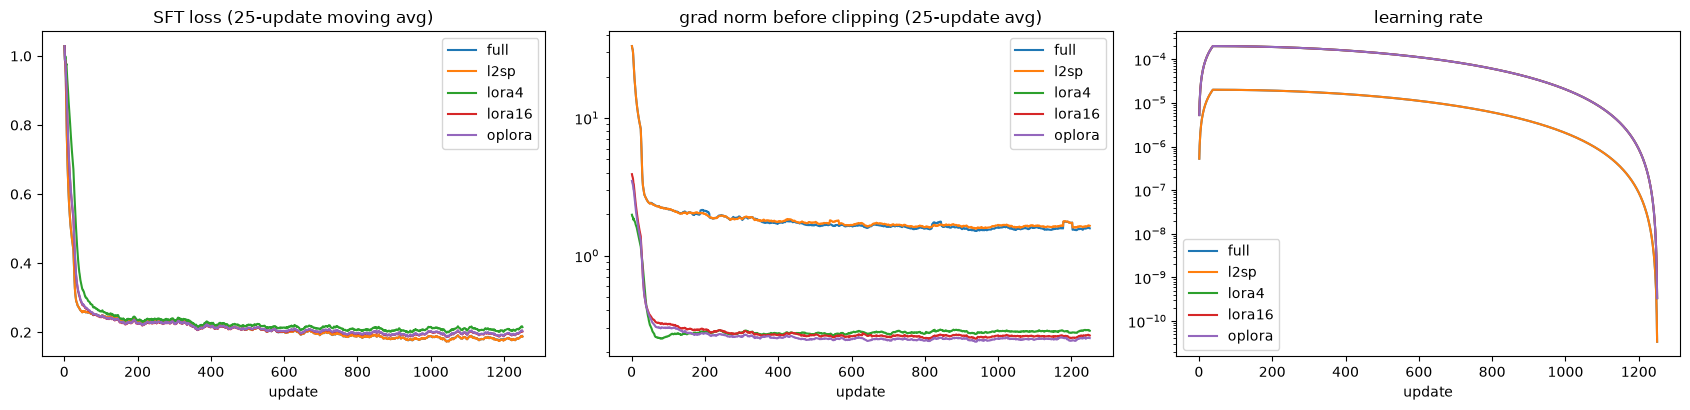

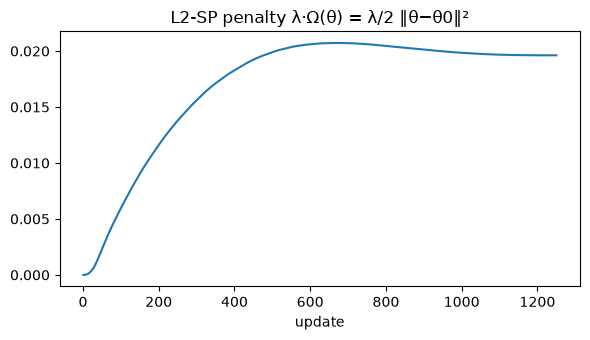

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for m in METHODS:
    df = pd.read_json(f"{RES}/runs/{m}/metrics.jsonl", lines=True).sort_values("step").drop_duplicates("step", keep="last")
    ax[0].plot(df.step, df.sft_loss.rolling(25, min_periods=1).mean(), label=m)
    ax[1].plot(df.step, df.grad_norm.rolling(25, min_periods=1).mean(), label=m)
    ax[2].plot(df.step, df.lr, label=m)
    if m == "l2sp":
        lam = df.dropna(subset=["lam_omega"])
for a, t in zip(ax, ["SFT loss (25-update moving avg)", "grad norm before clipping (25-update avg)", "learning rate"]):
    a.set_title(t); a.set_xlabel("update"); a.legend()
ax[1].set_yscale("log"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.5))
plt.plot(lam.step, lam.lam_omega)
plt.title("L2-SP penalty λ·Ω(θ) = λ/2 ‖θ−θ0‖²"); plt.xlabel("update"); plt.tight_layout(); plt.show()

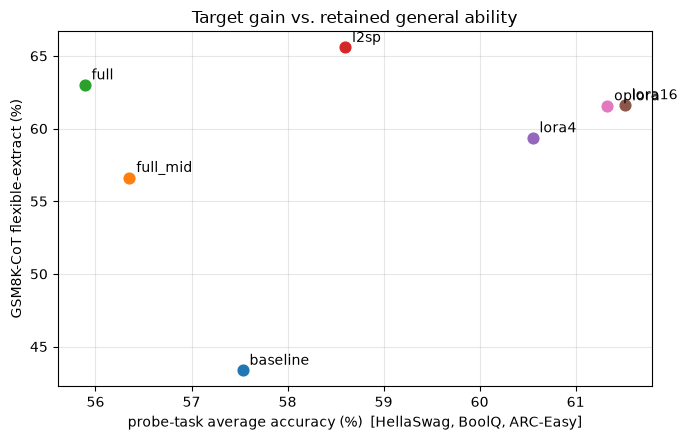

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c in CONDS:
    x, y = res.loc[c, probe].mean() * 100, res.loc[c, "GSM8K-CoT (flex)"] * 100
    ax.scatter(x, y, s=60); ax.annotate(c, (x, y), textcoords="offset points", xytext=(5, 4))
ax.set_xlabel("probe-task average accuracy (%)  [HellaSwag, BoolQ, ARC-Easy]")
ax.set_ylabel("GSM8K-CoT flexible-extract (%)")
ax.set_title("Target gain vs. retained general ability"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## Notes on the numbers

* **GSM8K strict-match is 0.0 for every condition, including the base model.** The `strict-match` filter of
  `gsm8k_cot` only accepts the few-shot "The answer is X." phrasing; zero-shot chat answers (MetaMathQA style,
  "The answer is: X" / boxed) never match it. `flexible-extract` (last number in the answer) is the meaningful metric
  and is what the tables use.
* Every run had 0 skipped (overflowed) fp16 updates.
* LoRA merge check: max |Δlogit| between the adapter model and the merged fp16 export is reported per run above
  (fp16 rounding of the merged weights).
* Raw per-sample lm-eval outputs (`log_samples=True`) are in the Kaggle job outputs; `results/evals` keeps the
  aggregate metrics and configs only.